In [1]:
#from libpysal.weights.contiguity import Queen #, higher_order
from libpysal.weights import higher_order, Queen
from splot.esda import plot_local_autocorrelation, lisa_cluster
from esda.moran import Moran_Local_BV, Moran_Local

from matplotlib import pyplot as plt

import geopandas as gpd
import pandas as pd
import h3pandas
import numpy as np

In [2]:
sp = gpd.read_file("../data/sp.geojson")

In [3]:
housing13 = pd.read_csv(f"../data/address/origins__2013.csv", sep=';')
housing13 = housing13.groupby("h3_09").agg({"N_HOUSING": 'sum'}).reset_index()
housing22 = pd.read_csv(f"../data/address/origins__2022.csv", sep=';')
housing22 = housing22.groupby("h3_09").agg({"N_HOUSING": 'sum'}).reset_index()
housing = housing13.merge(housing22, on="h3_09", suffixes=["___13", "___22"])
del housing13
del housing22
housing = housing.set_index("h3_09")
housing = housing.h3.h3_to_geo_boundary()
housing["delta_housing"] = housing.N_HOUSING___22 - housing.N_HOUSING___13


In [4]:
wHousing = Queen.from_dataframe(housing)
wHousing2 = higher_order(wHousing, k=2, lower_order=True)

wHousing.transform = 'r'
wHousing2.transform = 'r'

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_70492/3988209364.py:1: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wHousing = Queen.from_dataframe(housing)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 22 disconnected components.
 There are 3 islands with ids: 5546, 7761, 10047.
  warnings.warn(message)


('WARNING: ', 5546, ' is an island (no neighbors)')
('WARNING: ', 7761, ' is an island (no neighbors)')
('WARNING: ', 10047, ' is an island (no neighbors)')
('WARNING: ', 5546, ' is an island (no neighbors)')
('WARNING: ', 6897, ' is an island (no neighbors)')
('WARNING: ', 6901, ' is an island (no neighbors)')
('WARNING: ', 7761, ' is an island (no neighbors)')
('WARNING: ', 8623, ' is an island (no neighbors)')
('WARNING: ', 8628, ' is an island (no neighbors)')
('WARNING: ', 10047, ' is an island (no neighbors)')
('WARNING: ', 10377, ' is an island (no neighbors)')
('WARNING: ', 10378, ' is an island (no neighbors)')


/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 27 disconnected components.
 There are 9 islands with ids: 5546, 6897, 6901, 7761, 8623, 8628, 10047, 10377, 10378.
  warnings.warn(message)


/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


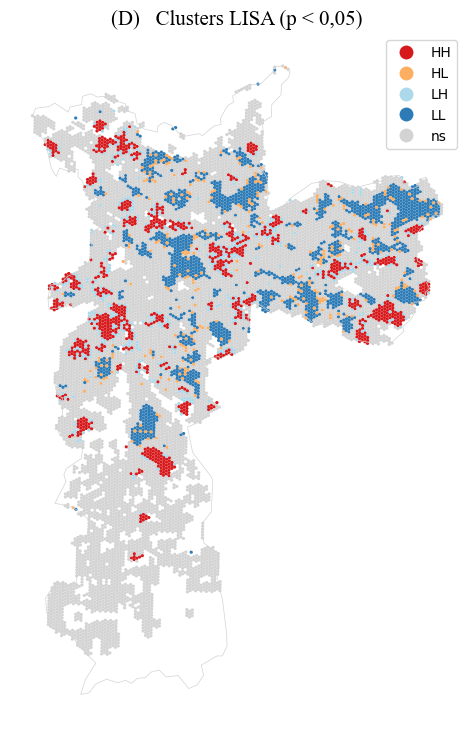

In [6]:
y = housing.delta_housing.values
moranLoc = Moran_Local(y, wHousing2)
coisa, ax = lisa_cluster(moranLoc, housing, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=15)
plt.savefig(f'./localMoran_deltaHousing2.png', dpi=900)

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


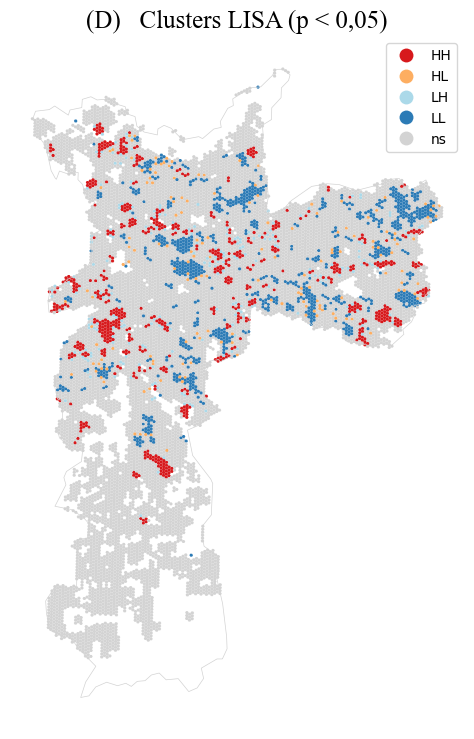

In [11]:
y = housing.delta_housing.values
moranLoc = Moran_Local(y, wHousing)
coisa, ax = lisa_cluster(moranLoc, housing, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=18)
plt.savefig(f'./localMoran_deltaHousing.png', dpi=900)

In [6]:
jobs13 = pd.read_csv(f"../data/address/destinations__2013.csv", sep=';').rename(columns={"id_hex": "h3_09"})
jobs13 = jobs13.groupby("h3_09").agg({"T001": 'sum'}).reset_index()
jobs22 = pd.read_csv(f"../data/address/destinations__2021.csv", sep=';').rename(columns={"id_hex": "h3_09"})
jobs22 = jobs22.groupby("h3_09").agg({"T001": 'sum'}).reset_index()
jobs = jobs13.merge(jobs22, on="h3_09", suffixes=["___13", "___22"])
del jobs13
del jobs22
jobs = jobs.set_index("h3_09")
jobs = jobs.h3.h3_to_geo_boundary()
jobs["delta_jobs"] = jobs.T001___22 - jobs.T001___13

wJobs = Queen.from_dataframe(jobs)
wJobs2 = higher_order(wJobs, k=2, lower_order=True)

wJobs.transform = 'r'
wJobs2.transform = 'r'


/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_70492/643188617.py:12: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  wJobs = Queen.from_dataframe(jobs)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 98 disconnected components.
 There are 66 islands with ids: 271, 562, 893, 1001, 1814, 4837, 4840, 4842, 4845, 4852, 4853, 4854, 4862, 4863, 4864, 4871, 4874, 4879, 4892, 4893, 4894, 4919, 4973, 4988, 4989, 5038, 5072, 5100, 5101, 5108, 5114, 5115, 5117, 5132, 5139, 5140, 5149, 5150, 5158, 5159, 5160, 5162, 5234, 5244, 5572, 5626, 6115, 6159, 6249, 7439, 7440, 7680, 7751, 7894, 7921, 7924, 7927, 7928, 7930, 7933, 7934, 7935, 7940, 7941, 7942, 7943.
  warnings.warn(message)


('WARNING: ', 271, ' is an island (no neighbors)')
('WARNING: ', 562, ' is an island (no neighbors)')
('WARNING: ', 893, ' is an island (no neighbors)')
('WARNING: ', 1001, ' is an island (no neighbors)')
('WARNING: ', 1814, ' is an island (no neighbors)')
('WARNING: ', 4837, ' is an island (no neighbors)')
('WARNING: ', 4840, ' is an island (no neighbors)')
('WARNING: ', 4842, ' is an island (no neighbors)')
('WARNING: ', 4845, ' is an island (no neighbors)')
('WARNING: ', 4852, ' is an island (no neighbors)')
('WARNING: ', 4853, ' is an island (no neighbors)')
('WARNING: ', 4854, ' is an island (no neighbors)')
('WARNING: ', 4862, ' is an island (no neighbors)')
('WARNING: ', 4863, ' is an island (no neighbors)')
('WARNING: ', 4864, ' is an island (no neighbors)')
('WARNING: ', 4871, ' is an island (no neighbors)')
('WARNING: ', 4874, ' is an island (no neighbors)')
('WARNING: ', 4879, ' is an island (no neighbors)')
('WARNING: ', 4892, ' is an island (no neighbors)')
('WARNING: ', 4

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 112 disconnected components.
 There are 90 islands with ids: 271, 557, 558, 562, 893, 1001, 1814, 2367, 2368, 4597, 4598, 4837, 4838, 4840, 4842, 4843, 4844, 4845, 4852, 4853, 4854, 4862, 4863, 4864, 4871, 4874, 4879, 4892, 4893, 4894, 4919, 4973, 4988, 4989, 5038, 5072, 5100, 5101, 5108, 5112, 5114, 5115, 5117, 5132, 5139, 5140, 5149, 5150, 5158, 5159, 5160, 5161, 5162, 5234, 5244, 5246, 5572, 5626, 5644, 5665, 6115, 6159, 6249, 7439, 7440, 7680, 7681, 7751, 7894, 7921, 7922, 7923, 7924, 7925, 7926, 7927, 7928, 7930, 7932, 7933, 7934, 7935, 7936, 7937, 7938, 7939, 7940, 7941, 7942, 7943.
  warnings.warn(message)


/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


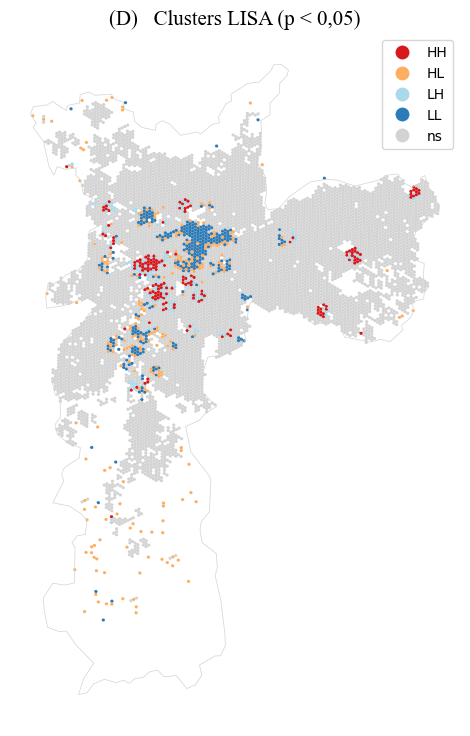

In [8]:
yJobs = jobs.delta_jobs.values
moranLocJobs2 = Moran_Local(yJobs, wJobs2)
#realDeltas = plot_local_autocorrelation(moranLocJobs, jobs, 'delta_jobs')

coisa, ax = lisa_cluster(moranLocJobs2, jobs, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=15)
plt.savefig(f'./localMoran_deltaJobs2.png', dpi=900)

/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/esda/moran.py:1059: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


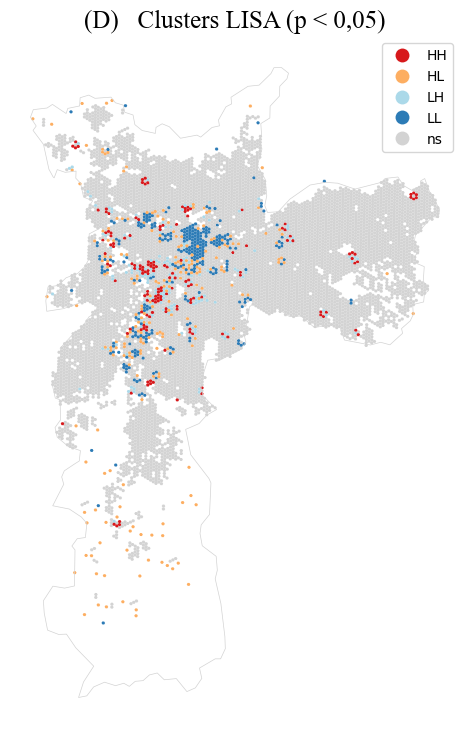

In [10]:
yJobs = jobs.delta_jobs.values
moranLocJobs = Moran_Local(yJobs, wJobs)
#realDeltas = plot_local_autocorrelation(moranLocJobs, jobs, 'delta_jobs')

coisa, ax = lisa_cluster(moranLocJobs, jobs, p=0.05, figsize=(12, 9))
sp.plot(ax=ax, edgecolor='lightgray', facecolor='none', linewidth=0.5, zorder=1)
ax.set_title("(D)   Clusters LISA (p < 0,05)", fontfamily="Times New Roman", fontsize=18)
plt.savefig(f'./localMoran_deltaJobs.png', dpi=900)

In [35]:
access = pd.read_csv("/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/access/real___2013/active.csv", sep=';')

<Axes: ylabel='Frequency'>

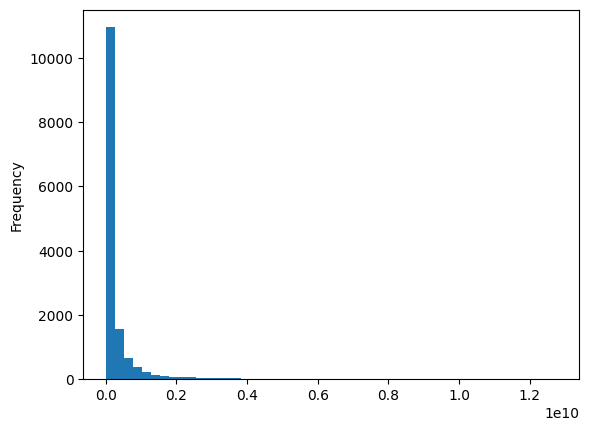

In [37]:
access.pond_T001.plot(kind="hist", bins=50)

In [38]:
import numpy as np

In [ ]:
access = access[access.pond_T001>0]

<Axes: ylabel='Frequency'>

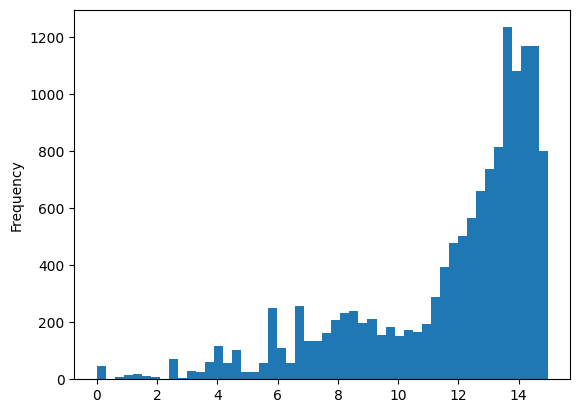

In [46]:
np.log(access[access.T001>0].T001).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

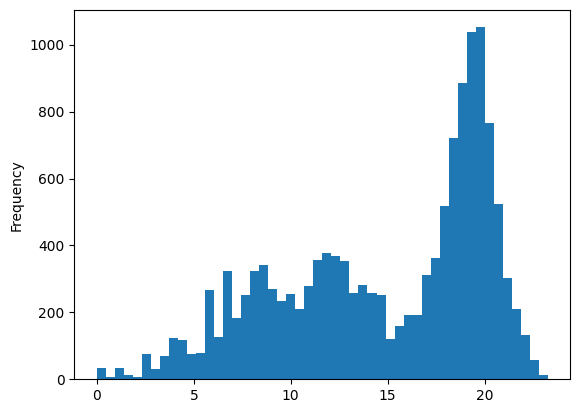

In [40]:
np.log(access[access.pond_T001>0].pond_T001).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

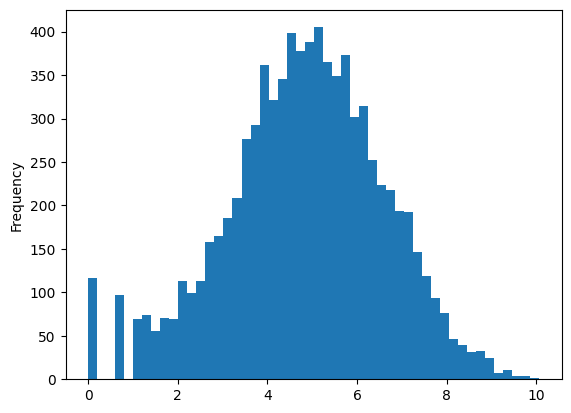

In [45]:
np.log(jobs[jobs.T001___13>0].T001___13).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

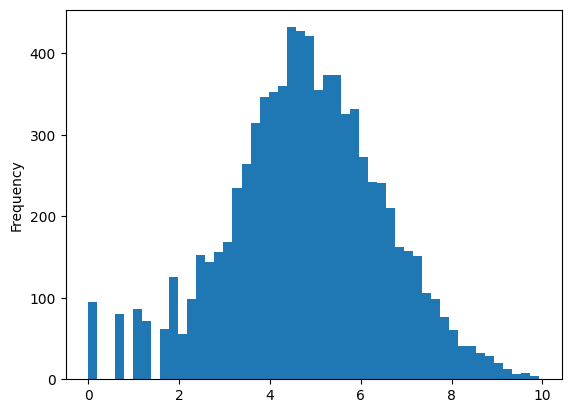

In [47]:
np.log(jobs[jobs.T001___22>0].T001___22).plot(kind="hist", bins=50)

<Axes: ylabel='Frequency'>

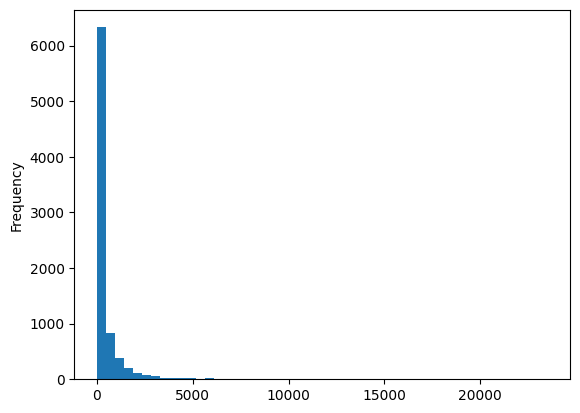

In [44]:
(jobs[jobs.T001___13>0].T001___13).plot(kind="hist", bins=50)